# Laboratorium 2B, cz. 2: COCO, hybryda, fine-tuned i porownanie

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

import utils_common as w
import utils_yolo as y

pd.set_option("display.width", 160)
(w.LAB5 / "wykresy").mkdir(exist_ok=True)
manifest = w.make_manifest()
val, test = manifest["splits"]["val"], manifest["splits"]["test"]
gt_val, gt_test = w.load_gt(val), w.load_gt(test)

# klasyczny detektor to las losowy z notebooka lab4: stamtad bierzemy predykcje testu i czas
LAB4_EXP = w.DATA_ROOT / "outputs" / "official_1500_seed42"
rf_pred = w.read_json(LAB4_EXP / "simple_rf_predictions.json")["predictions"]
rf_fps = w.read_json(LAB4_EXP / "rf_fps.json")["fps"]


## Zadanie 1: YOLOv8n z COCO
Dobor imgsz i progu pewnosci tylko na val.

In [3]:
coco = YOLO(str(w.LAB5 / "yolov8n.pt"))
raw_val, rows = {}, []
for imgsz in (640, 960, 1280):
    raw_val[imgsz] = y.raw_predict(coco, val, imgsz)
    for conf in (.05, .1, .15, .25, .35, .5):
        m = w.evaluate(val, y.to_items(raw_val[imgsz], conf), gt_val)["metrics"].set_index("class")
        for c in w.CLASSES:
            rows.append({"imgsz": imgsz, "conf": conf, "class": c, **m.loc[c, ["TP", "FP", "FN", "precision", "recall", "F1"]]})
grid = pd.DataFrame(rows)
print(grid[grid["class"] == "traffic_light"].round(3).to_string(index=False))
best = grid[grid["class"] == "traffic_light"].sort_values("F1").iloc[-1]
IMGSZ, CONF = int(best["imgsz"]), float(best["conf"])
print("wybrane (val, F1 swiatel):", IMGSZ, CONF)

 imgsz  conf         class    TP    FP    FN  precision  recall    F1
   640  0.05 traffic_light  72.0 353.0 341.0      0.169   0.174 0.172
   640  0.10 traffic_light  55.0 148.0 358.0      0.271   0.133 0.179
   640  0.15 traffic_light  45.0  83.0 368.0      0.352   0.109 0.166
   640  0.25 traffic_light  31.0  32.0 382.0      0.492   0.075 0.130
   640  0.35 traffic_light  21.0   9.0 392.0      0.700   0.051 0.095
   640  0.50 traffic_light  11.0   4.0 402.0      0.733   0.027 0.051
   960  0.05 traffic_light 141.0 519.0 272.0      0.214   0.341 0.263
   960  0.10 traffic_light 111.0 232.0 302.0      0.324   0.269 0.294
   960  0.15 traffic_light  91.0 118.0 322.0      0.435   0.220 0.293
   960  0.25 traffic_light  52.0  59.0 361.0      0.468   0.126 0.198
   960  0.35 traffic_light  30.0  30.0 383.0      0.500   0.073 0.127
   960  0.50 traffic_light  16.0   9.0 397.0      0.640   0.039 0.073
  1280  0.05 traffic_light 184.0 735.0 229.0      0.200   0.446 0.276
  1280  0.10 traffic

## Zadanie 2: hybryda, kolor swiatla z HSV
Progi saturacji i jasnosci tez tylko na val.

In [4]:
rows = []
for sat in (60, 80, 100, 120):
    for value in (65, 100):
        r = w.evaluate(val, y.to_items(raw_val[IMGSZ], CONF, y.color_fn_for(val, sat, value)), gt_val)
        rows.append({"sat": sat, "value": value, "matched": r["matched_lights"], "color_acc": r["color_acc"]})
hsv_grid = pd.DataFrame(rows)
print(hsv_grid.round(3).to_string(index=False))
bh = hsv_grid.sort_values("color_acc", kind="stable").iloc[-1]
P_COCO = {"imgsz": IMGSZ, "conf": CONF, "sat": int(bh["sat"]), "value": int(bh["value"])}
w.save_json(w.OUT / "yolo_coco_params.json", P_COCO)
print("wybrane:", P_COCO)

 sat  value  matched  color_acc
  60     65      149      0.711
  60    100      149      0.738
  80     65      149      0.752
  80    100      149      0.779
 100     65      149      0.725
 100    100      149      0.752
 120     65      149      0.718
 120    100      149      0.738
wybrane: {'imgsz': 1280, 'conf': 0.1, 'sat': 80, 'value': 100}


## Zadanie 3: fine-tuned YOLO, dobor progu na val

In [5]:
ft = YOLO(str(y.RUN / "weights" / "best.pt"))
ft_val = y.ft_raw(ft, val)
rows = []
for conf in (.05, .1, .15, .2, .25, .3, .4, .5):
    m = w.evaluate(val, y.ft_items(ft_val, conf), gt_val)["metrics"].set_index("class")
    rows.append({"conf": conf, "F1_sign": m.loc["traffic_sign", "F1"], "F1_light": m.loc["traffic_light", "F1"]})
grid_ft = pd.DataFrame(rows)
grid_ft["F1_mean"] = grid_ft[["F1_sign", "F1_light"]].mean(axis=1)
print(grid_ft.round(3).to_string(index=False))
CONF_FT = float(grid_ft.sort_values("F1_mean").iloc[-1]["conf"])
w.save_json(w.OUT / "yolo_ft_params.json", {"imgsz": 1280, "conf": CONF_FT})
print("wybrany conf (val, srednia F1 obu klas):", CONF_FT)

 conf  F1_sign  F1_light  F1_mean
 0.05    0.463     0.517    0.490
 0.10    0.534     0.575    0.554
 0.15    0.570     0.592    0.581
 0.20    0.580     0.603    0.592
 0.25    0.586     0.601    0.593
 0.30    0.582     0.584    0.583
 0.40    0.573     0.524    0.548
 0.50    0.544     0.416    0.480
wybrany conf (val, srednia F1 obu klas): 0.25


## Zadanie 4: test, wszystkie metody raz

In [6]:
images = {r["id"]: w.load_image(w.DATA_ROOT / r["image"]) for r in test}
items = {"klasyczna (lab4)": {r["id"]: rf_pred[r["id"]] for r in test},
         "hybryda (COCO + HSV)": {rid: y.hybrid_detect(coco, im, P_COCO) for rid, im in images.items()},
         "YOLO fine-tuned": y.ft_items({rid: y.ft_predict(ft, im, 1280, CONF_FT) for rid, im in images.items()}, CONF_FT)}
results = {name: w.evaluate(test, it, gt_test) for name, it in items.items()}
table = pd.concat([r["metrics"].assign(metoda=name) for name, r in results.items()])[["metoda", "class", "TP", "FP", "FN", "precision", "recall", "F1"]]
table.to_csv(w.OUT / "porownanie_test.csv", index=False)
print(table.round(3).to_string(index=False))

              metoda         class  TP  FP  FN  precision  recall    F1
    klasyczna (lab4)  traffic_sign  87 303 890      0.223   0.089 0.127
    klasyczna (lab4) traffic_light  78 431 706      0.153   0.099 0.121
hybryda (COCO + HSV)  traffic_sign   8   3 969      0.727   0.008 0.016
hybryda (COCO + HSV) traffic_light 267 543 517      0.330   0.341 0.335
     YOLO fine-tuned  traffic_sign 555 315 422      0.638   0.568 0.601
     YOLO fine-tuned traffic_light 397 194 387      0.672   0.506 0.577


## Kolor (tylko swiatla poprawnie zlokalizowane)

In [7]:
for name, r in results.items():
    print(name, "| dopasowanych swiatel:", r["matched_lights"], "| trafnosc koloru:", round(r["color_acc"], 3))
    print(r["confusion"])

klasyczna (lab4) | dopasowanych swiatel: 78 | trafnosc koloru: 0.808
         red  yellow  green  unknown
red       12       0      0        1
yellow     0       1      0        0
green      0       2     50        0
unknown    0      12      0        0
hybryda (COCO + HSV) | dopasowanych swiatel: 267 | trafnosc koloru: 0.581
         red  yellow  green  unknown
red       53       3      1        8
yellow     4       2      0        1
green      0      17     85       10
unknown    8      56      4       15
YOLO fine-tuned | dopasowanych swiatel: 397 | trafnosc koloru: 0.932
         red  yellow  green  unknown
red       66       0      0       11
yellow     5       3      0        0
green      0       0    192        4
unknown    3       0      4      109


## Czas na tym samym komputerze (100 zdjec; CPU hybrydy i fine-tuned na 30)

In [8]:
ims = list(images.values())[:100]
fps = pd.DataFrame([
    {"metoda": "klasyczna (CPU)", "fps": rf_fps},
    {"metoda": "hybryda GPU", "fps": y.time_fn(lambda im: y.hybrid_detect(coco, im, P_COCO), ims)},
    {"metoda": "hybryda CPU", "fps": y.time_fn(lambda im: y.hybrid_detect(coco, im, P_COCO, "cpu"), ims, 30)},
    {"metoda": "YOLO fine-tuned GPU", "fps": y.time_fn(lambda im: y.ft_predict(ft, im, 1280, CONF_FT), ims)},
    {"metoda": "YOLO fine-tuned CPU", "fps": y.time_fn(lambda im: y.ft_predict(ft, im, 1280, CONF_FT, "cpu"), ims, 30)}])
fps.to_csv(w.OUT / "fps.csv", index=False)
print(fps.round(1).to_string(index=False))

             metoda  fps
    klasyczna (CPU)  3.8
        hybryda GPU 32.1
        hybryda CPU  4.2
YOLO fine-tuned GPU 32.2
YOLO fine-tuned CPU  3.9


## Zadanie 5: przyklady bledow

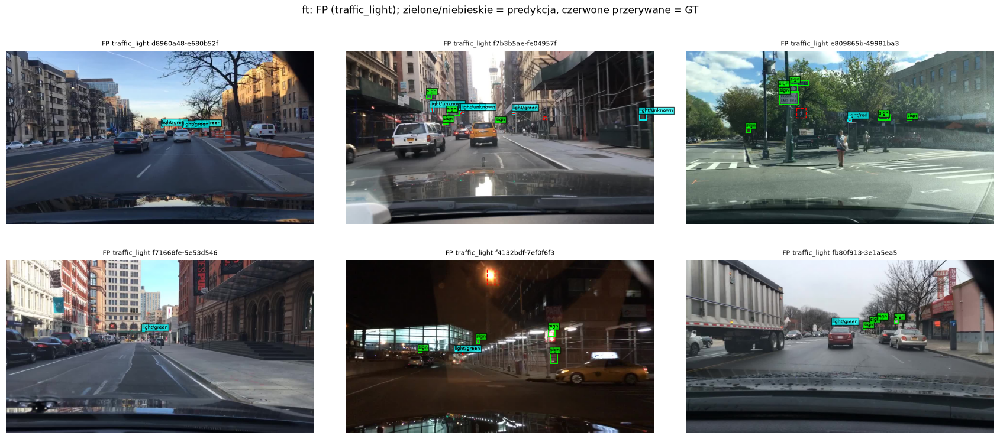

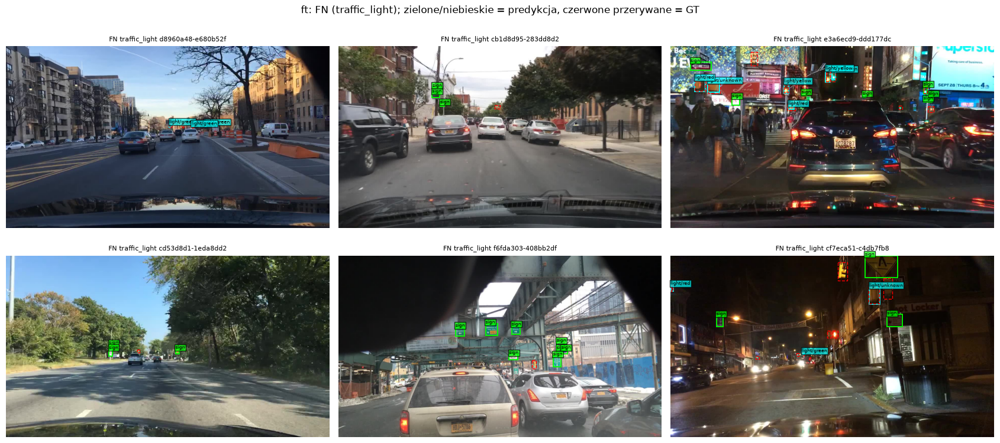

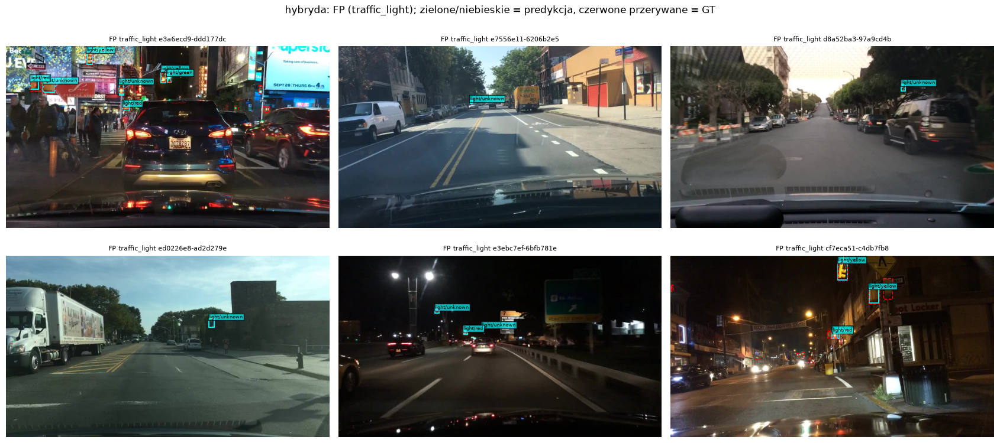

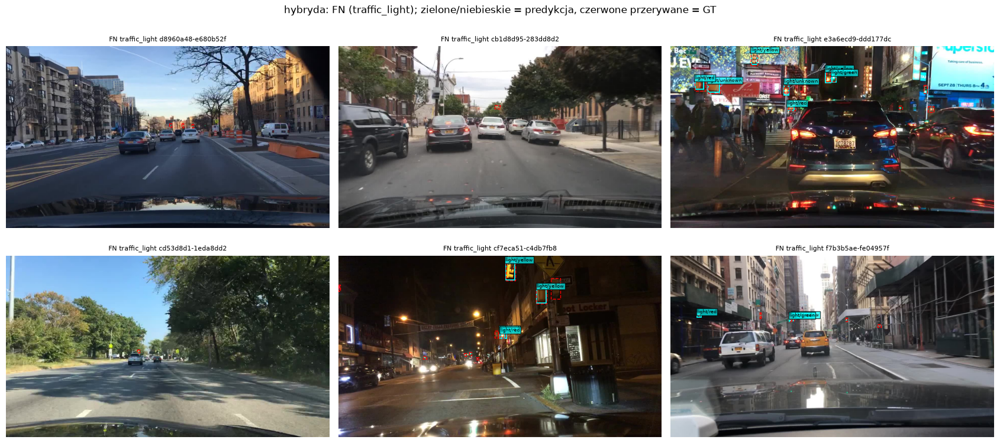

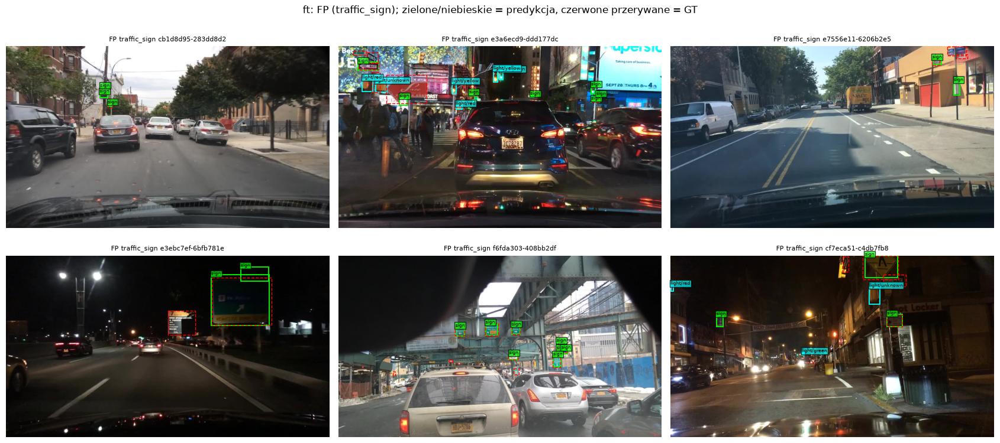

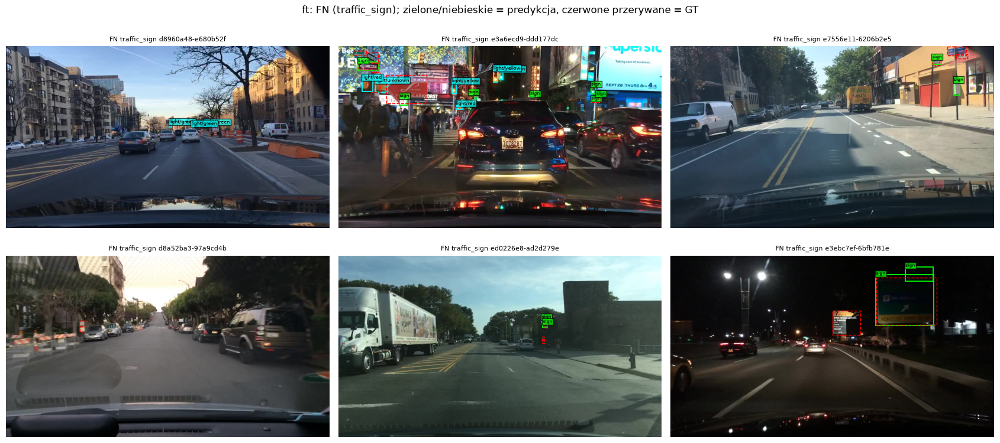

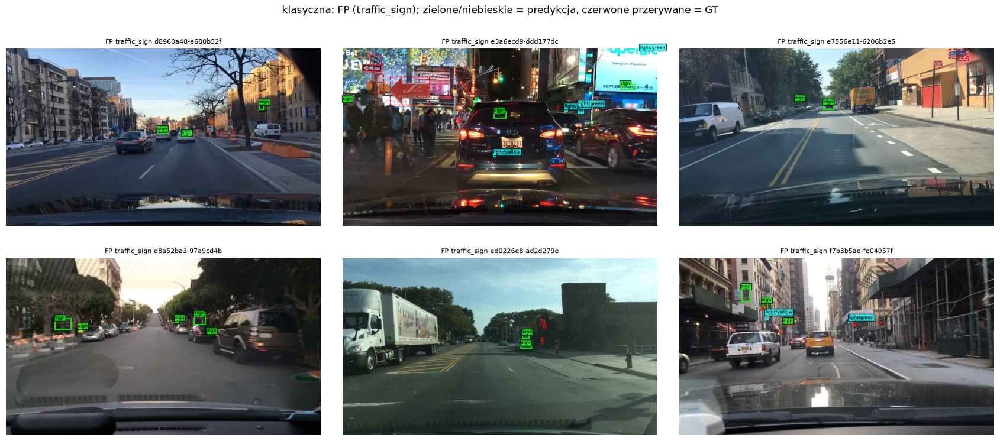

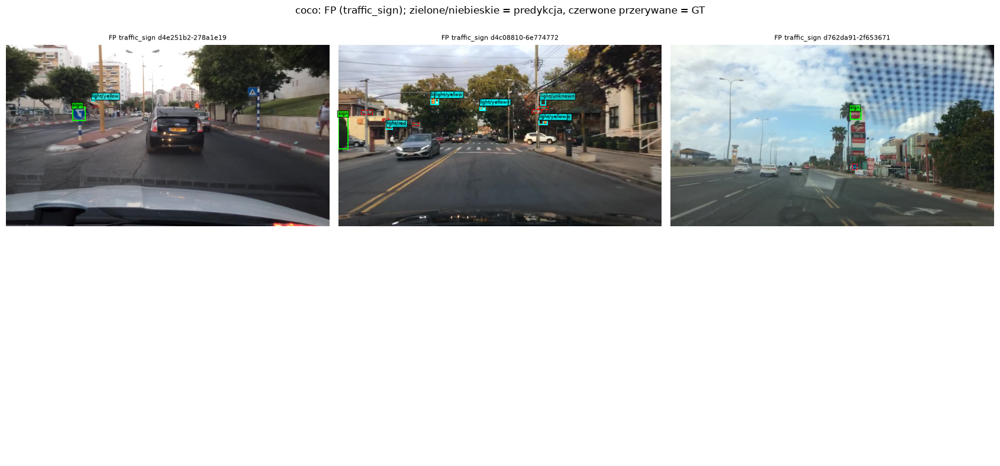

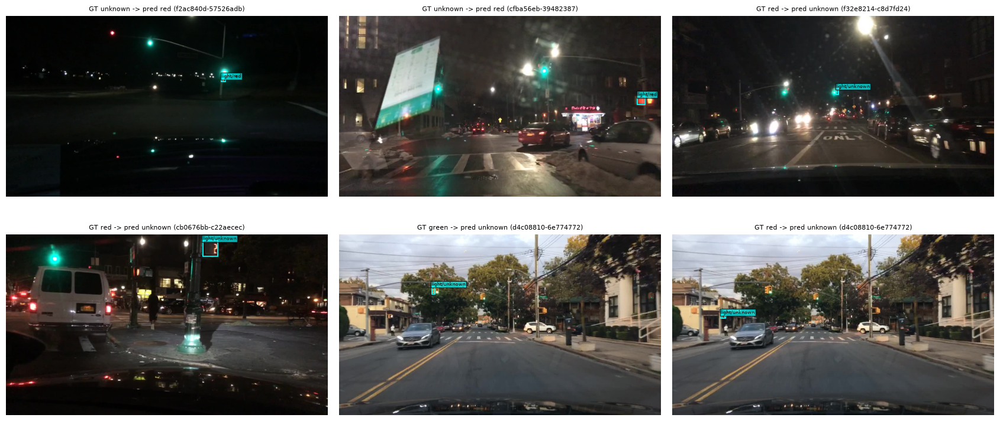

In [9]:
for name, tag in (("YOLO fine-tuned", "ft"), ("hybryda (COCO + HSV)", "hybryda")):
    for kind in ("FP", "FN"):
        y.show_errors(results[name], items[name], images, gt_test, tag, kind, "traffic_light")
for kind in ("FP", "FN"):
    y.show_errors(results["YOLO fine-tuned"], items["YOLO fine-tuned"], images, gt_test, "ft", kind, "traffic_sign")
y.show_errors(results["klasyczna (lab4)"], items["klasyczna (lab4)"], images, gt_test, "klasyczna", "FP", "traffic_sign")
y.show_errors(results["hybryda (COCO + HSV)"], items["hybryda (COCO + HSV)"], images, gt_test, "coco", "FP", "traffic_sign")
wrong = [p for p in results["YOLO fine-tuned"]["color_pairs"] if p[0] != p[1]][:6]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (a, p, rid, box) in zip(axes.ravel(), wrong):
    w.draw(images[rid], [{"class": "traffic_light", "box": box, "color": p}], ax, f"GT {a} -> pred {p} ({rid})")
for ax in axes.ravel()[len(wrong):]:
    ax.axis("off")
fig.tight_layout(); fig.savefig(w.LAB5 / "wykresy" / "ft_kolor_bledy.png", dpi=100)
plt.show()